In [1]:
# Informe EDA: exportación portable de la vista revisada
# Todas las celdas son de código; las explicaciones se muestran al ejecutarlas.
# Dependencias: pandas, numpy, matplotlib, matplotlib-inline, IPython, ipykernel.
from __future__ import annotations
import base64
import gzip
import hashlib
import html
import json
import platform
import importlib.metadata
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import HTML, display
%matplotlib inline
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 10, "figure.facecolor": "white"})
CONFIG = {"municipality_codes": None, "minimum_municipal_rows": 12}

Matplotlib is building the font cache; this may take a moment.


In [2]:
# Included reviewed data: no source query or pipeline execution.
BUNDLE_SHA256 = '3fc98d6f61252e091192c261725995f1a4e702ef12b988e3a94bc4e8349ef4f4'
_BUNDLE_BASE64 = (
    '...'
)
_snapshot_bytes = gzip.decompress(base64.b64decode(_BUNDLE_BASE64))
assert hashlib.sha256(_snapshot_bytes).hexdigest() == BUNDLE_SHA256, "Snapshot integrity check failed"
reviewed = json.loads(_snapshot_bytes)
frames = {name: pd.DataFrame(rows) for name, rows in reviewed["queries"].items()}
seasonality_profile = pd.DataFrame(reviewed["seasonality_full_profile"])

In [3]:
# Presentación compartida: texto y tablas editables desde estas celdas.
def show_text(text: str, title: bool = False) -> None:
    """Muestra texto preservando párrafos y caracteres originales.

    Args:
        text: Narrativa capturada de la vista actual.
        title: Si el texto representa el título del informe.
    """
    paragraphs = text.split("\n\n")
    blocks = []
    for index, paragraph in enumerate(paragraphs):
        tag = "h1" if title and index == 0 else "h2" if index == 0 else "p"
        blocks.append(f"<{tag}>{html.escape(paragraph).replace(chr(10), '<br>')}</{tag}>")
    display(HTML('<div style="max-width:1050px;line-height:1.65;font-family:Arial,sans-serif">' + ''.join(blocks) + '</div>'))


def show_table(table: pd.DataFrame) -> None:
    """Muestra una tabla acotada con nombres legibles y valores exactos.

    Args:
        table: Tabla ya preparada para presentación.
    """
    display(HTML('<div style="overflow-x:auto;max-width:100%">' + table.to_html(index=False, escape=True) + '</div>'))

show_text(reviewed["context"]["artifact"]["title"], title=True)
show_text("Contexto de esta exportación\n\nVista: " + reviewed["context"]["viewUrl"] +
          "\nCorte descriptivo: 2024-12-31. Sin filtros, bloques ocultos o cambios de gráficas activos. "
          "No se extrajeron datos nuevos ni se entrenaron modelos. "
          "Los datos revisados y las narrativas están incluidos en este archivo; no necesita el servidor local para ejecutarse.")
show_text(reviewed["narratives"]["summary"])

In [4]:
# chapter1
show_text(reviewed["narratives"]['chapter1'])

In [5]:
# chapter2
show_text(reviewed["narratives"]['chapter2'])

In [6]:
# chapter3
show_text(reviewed["narratives"]['chapter3'])

In [7]:
# Tabla 1: mismos valores, columnas y selección de la vista del informe.
LABELS = {
    "rain_mm_month_sum": "Lluvia", "surface_runoff_mm_month_sum": "Escorrentía",
    "total_evaporation_mm_month_sum_ecmwf": "Evaporación",
    "solar_radiation_mj_m2_month_sum": "Radiación solar", "temp_mean_c_month_mean": "Temperatura",
    "dewpoint_mean_c_month_mean": "Punto de rocío", "soil_water_l1_month_mean": "Agua del suelo",
    "wind_u_ms_month_mean": "Viento U", "wind_v_ms_month_mean": "Viento V",
    "dengue_notifications_count": "Dengue", "dengue_grave_notifications_count": "Dengue grave",
}
missing = frames["missing"].loc[~frames["missing"]["variable"].str.startswith("y_")].copy()
missing_table = pd.DataFrame({
    "Variable": missing["variable"].map(LABELS),
    "Meses-municipio sin valor": missing["missing_rows"].astype(int),
    "% ausente": (missing["missing_pct"] * 100).map(lambda value: f"{value:.2f} %".replace('.', ',')),
    "Mayor hueco": missing["longest_missing_gap_months"].astype(int).astype(str) + " meses",
})
show_text("Los huecos climáticos se concentran en siete meses de 2006")
show_table(missing_table)

Variable,Meses-municipio sin valor,% ausente,Mayor hueco
Punto de rocío,532,"3,14 %",7 meses
Lluvia,532,"3,14 %",7 meses
Agua del suelo,532,"3,14 %",7 meses
Radiación solar,532,"3,14 %",7 meses
Escorrentía,532,"3,14 %",7 meses
Temperatura,532,"3,14 %",7 meses
Evaporación,532,"3,14 %",7 meses
Viento U,532,"3,14 %",7 meses
Viento V,532,"3,14 %",7 meses
Dengue grave,0,"0,00 %",0 meses


In [8]:
show_text(reviewed["narratives"]["chapter4"])

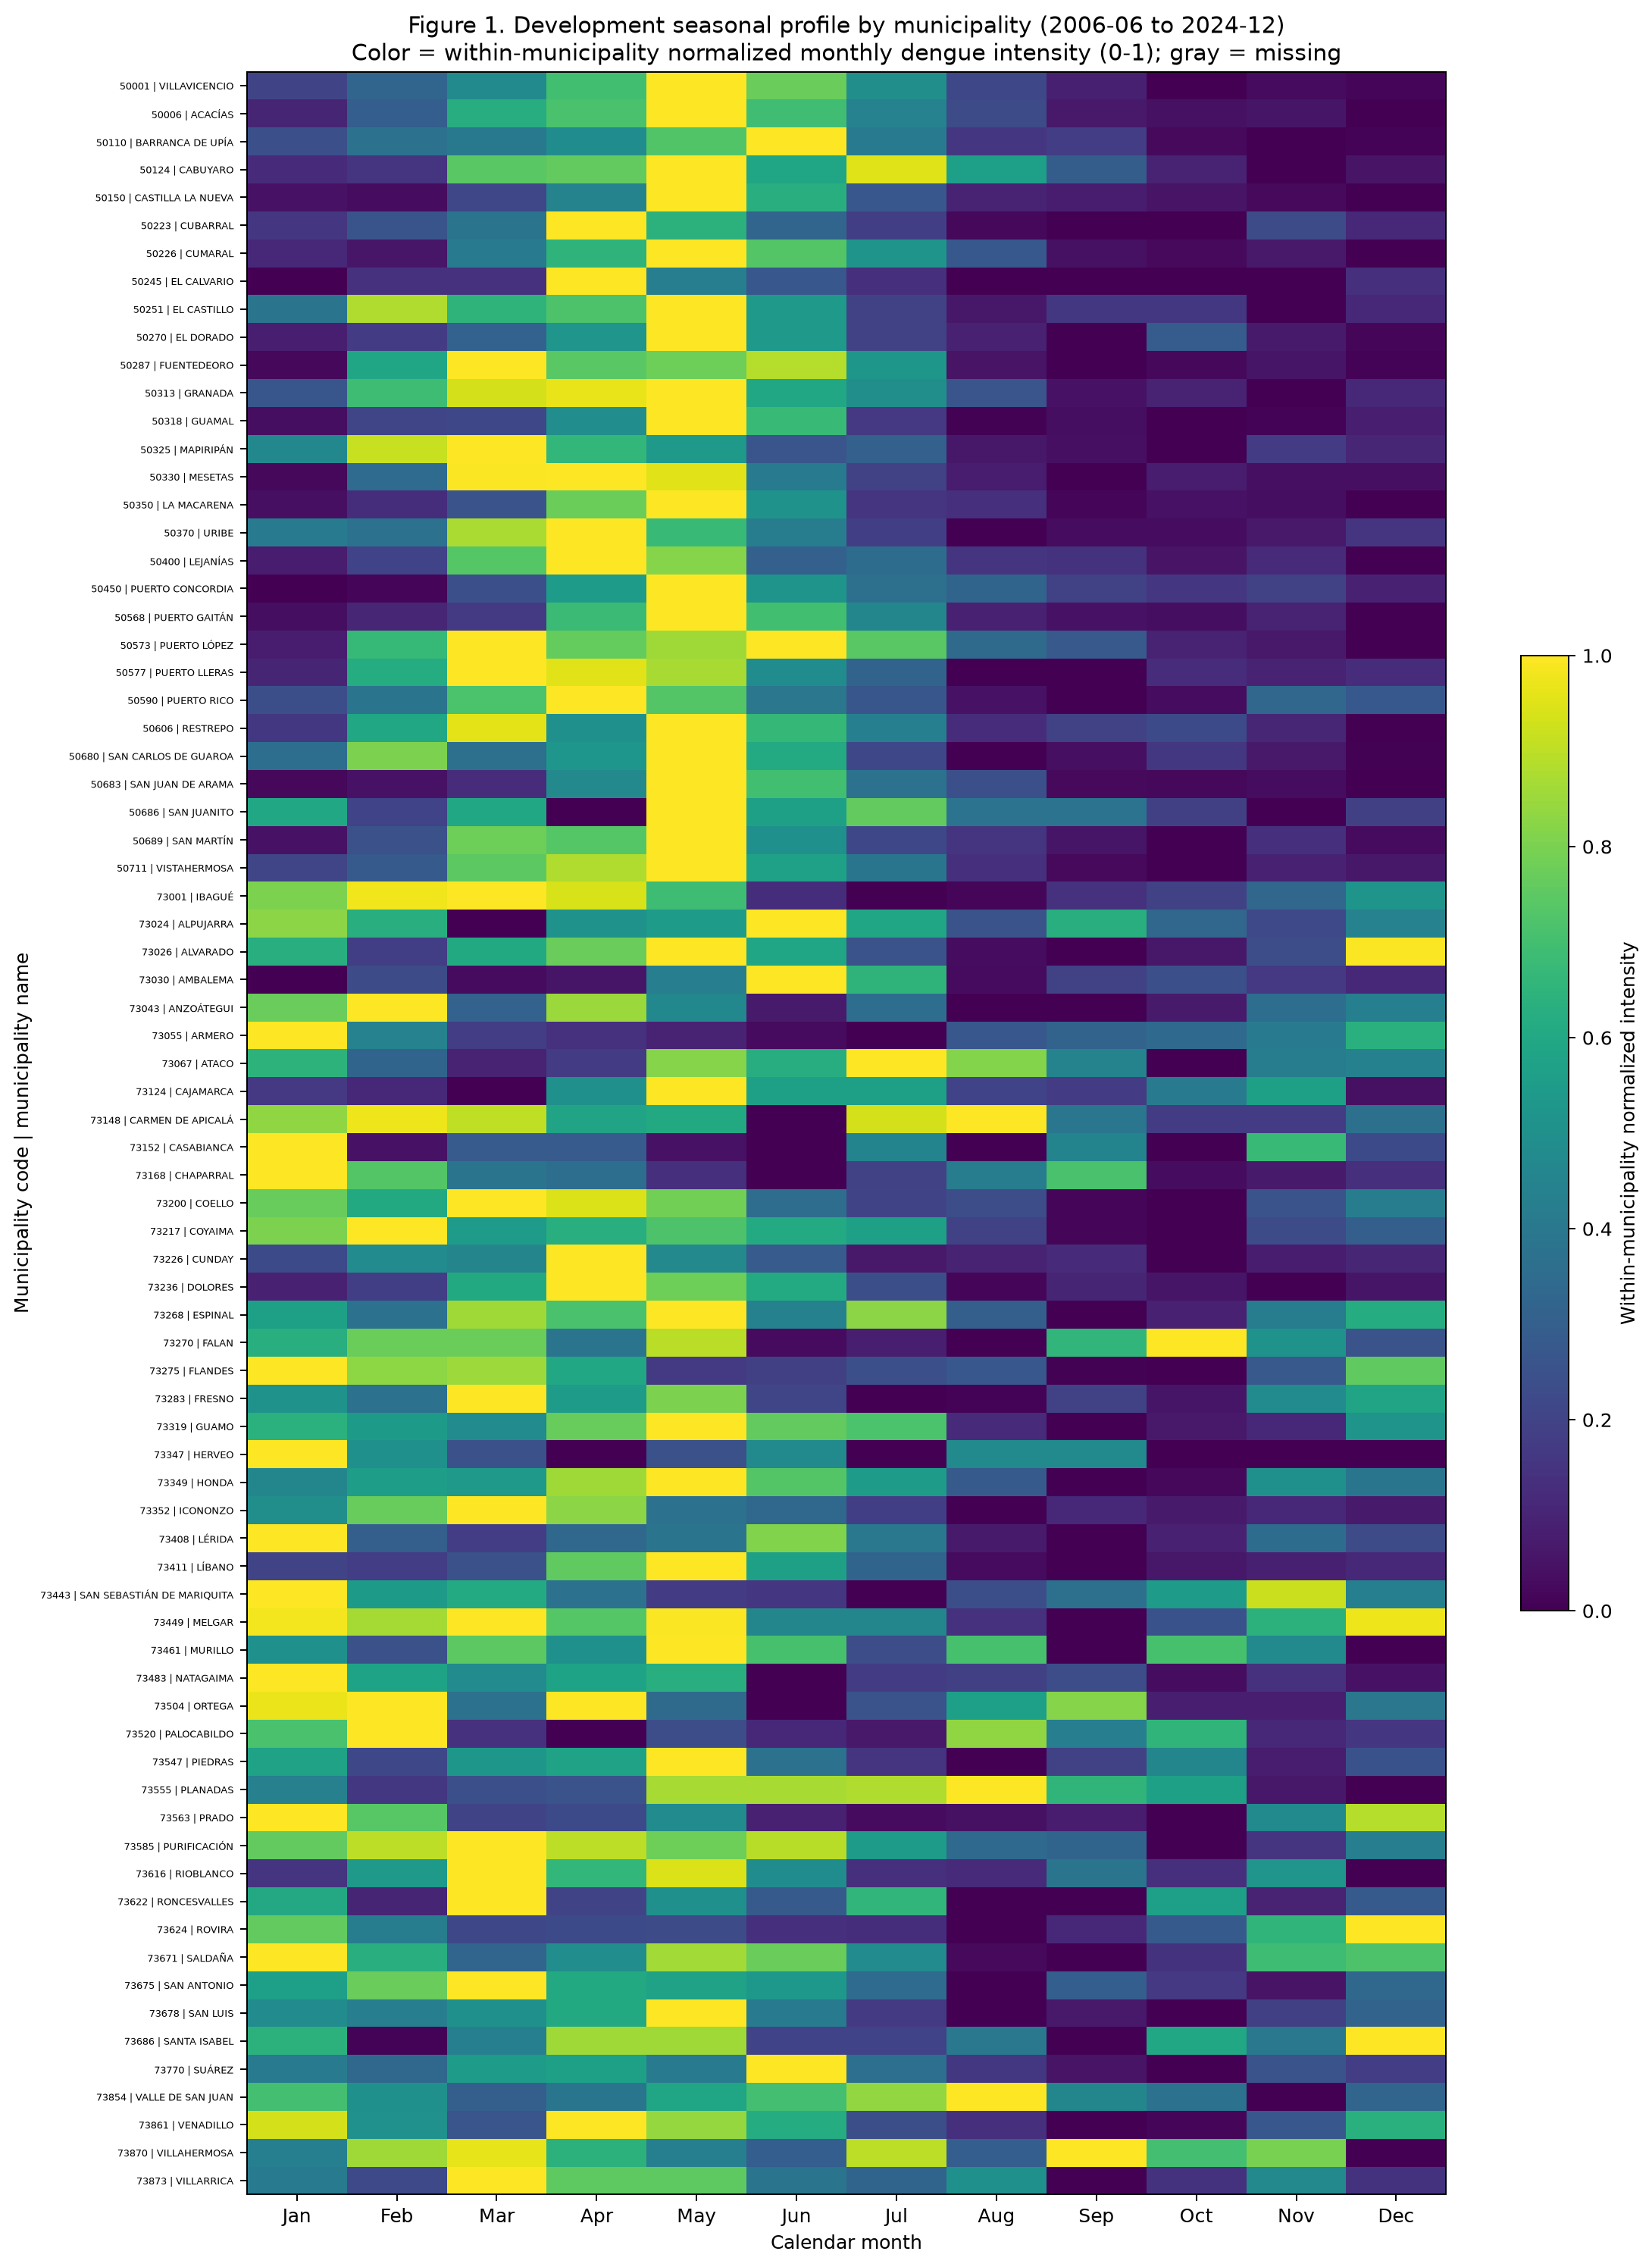

In [9]:
# Figura 1: cálculo y gráfica editables; no se incrusta una imagen de referencia.
def plot_seasonality(profile: pd.DataFrame, municipality_codes: list[int] | None = None):
    """Reconstruye los 12 valores mensuales de cada municipio de la vista.

    Args:
        profile: Promedios históricos revisados por municipio y mes.
        municipality_codes: Subconjunto opcional; None conserva los 76 municipios.

    Returns:
        Figura y matriz normalizada que se representa.
    """
    selected = profile.copy()
    if municipality_codes is not None:
        selected = selected[selected.municipality_code.isin(municipality_codes)]
    if selected.empty:
        raise ValueError("No existen municipios para la selección")
    pivot = selected.pivot(index=["department_code", "municipality_code", "municipality_name"],
                           columns="calendar_month", values="dengue_notifications_count").sort_index().reindex(columns=range(1, 13))
    matrix = pivot.copy().astype(float)
    for key, row in pivot.iterrows():
        lo, hi = row.min(), row.max()
        matrix.loc[key] = (row - lo) / (hi - lo) if hi > lo else row.where(row.isna(), 0.0 if hi == 0 else 0.5)
    fig, ax = plt.subplots(figsize=(13, max(10.0, 0.22 * len(matrix))), dpi=180)
    cmap = plt.colormaps["viridis"].copy()
    cmap.set_bad("#d9d9d9")
    image = ax.imshow(np.ma.masked_invalid(matrix.to_numpy()), aspect="auto", interpolation="nearest", cmap=cmap, vmin=0, vmax=1)
    ax.set_xticks(np.arange(12), ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
    labels = [f"{key[1]:05d} | {key[2]}" for key in matrix.index]
    ax.set_yticks(np.arange(len(matrix)), labels, fontsize=5)
    ax.set_xlabel("Calendar month")
    ax.set_ylabel("Municipality code | municipality name")
    ax.set_title("Figure 1. Development seasonal profile by municipality (2006-06 to 2024-12)\n"
                 "Color = within-municipality normalized monthly dengue intensity (0-1); gray = missing")
    fig.colorbar(image, ax=ax, shrink=0.45).set_label("Within-municipality normalized intensity")
    fig.tight_layout()
    return fig, matrix

show_text("Patrones mensuales dentro de cada municipio")
seasonality_figure, seasonality_matrix = plot_seasonality(seasonality_profile, CONFIG["municipality_codes"])
plt.show()
plt.close(seasonality_figure)

In [10]:
# Chapter 5: corrected conclusion; the old false statement is replaced.
show_text(reviewed["narratives"]["chapter5"])
display(HTML('<p>Active canonical reference: <a href="DATA-01-Priority%20Field%20Matrix.md">DATA-01-Priority Field Matrix</a>. All 69 fields are inventoried; six operational definitions remain insufficient under DEC-033.</p>'))

In [11]:
show_text(reviewed["narratives"]["chapter6"])

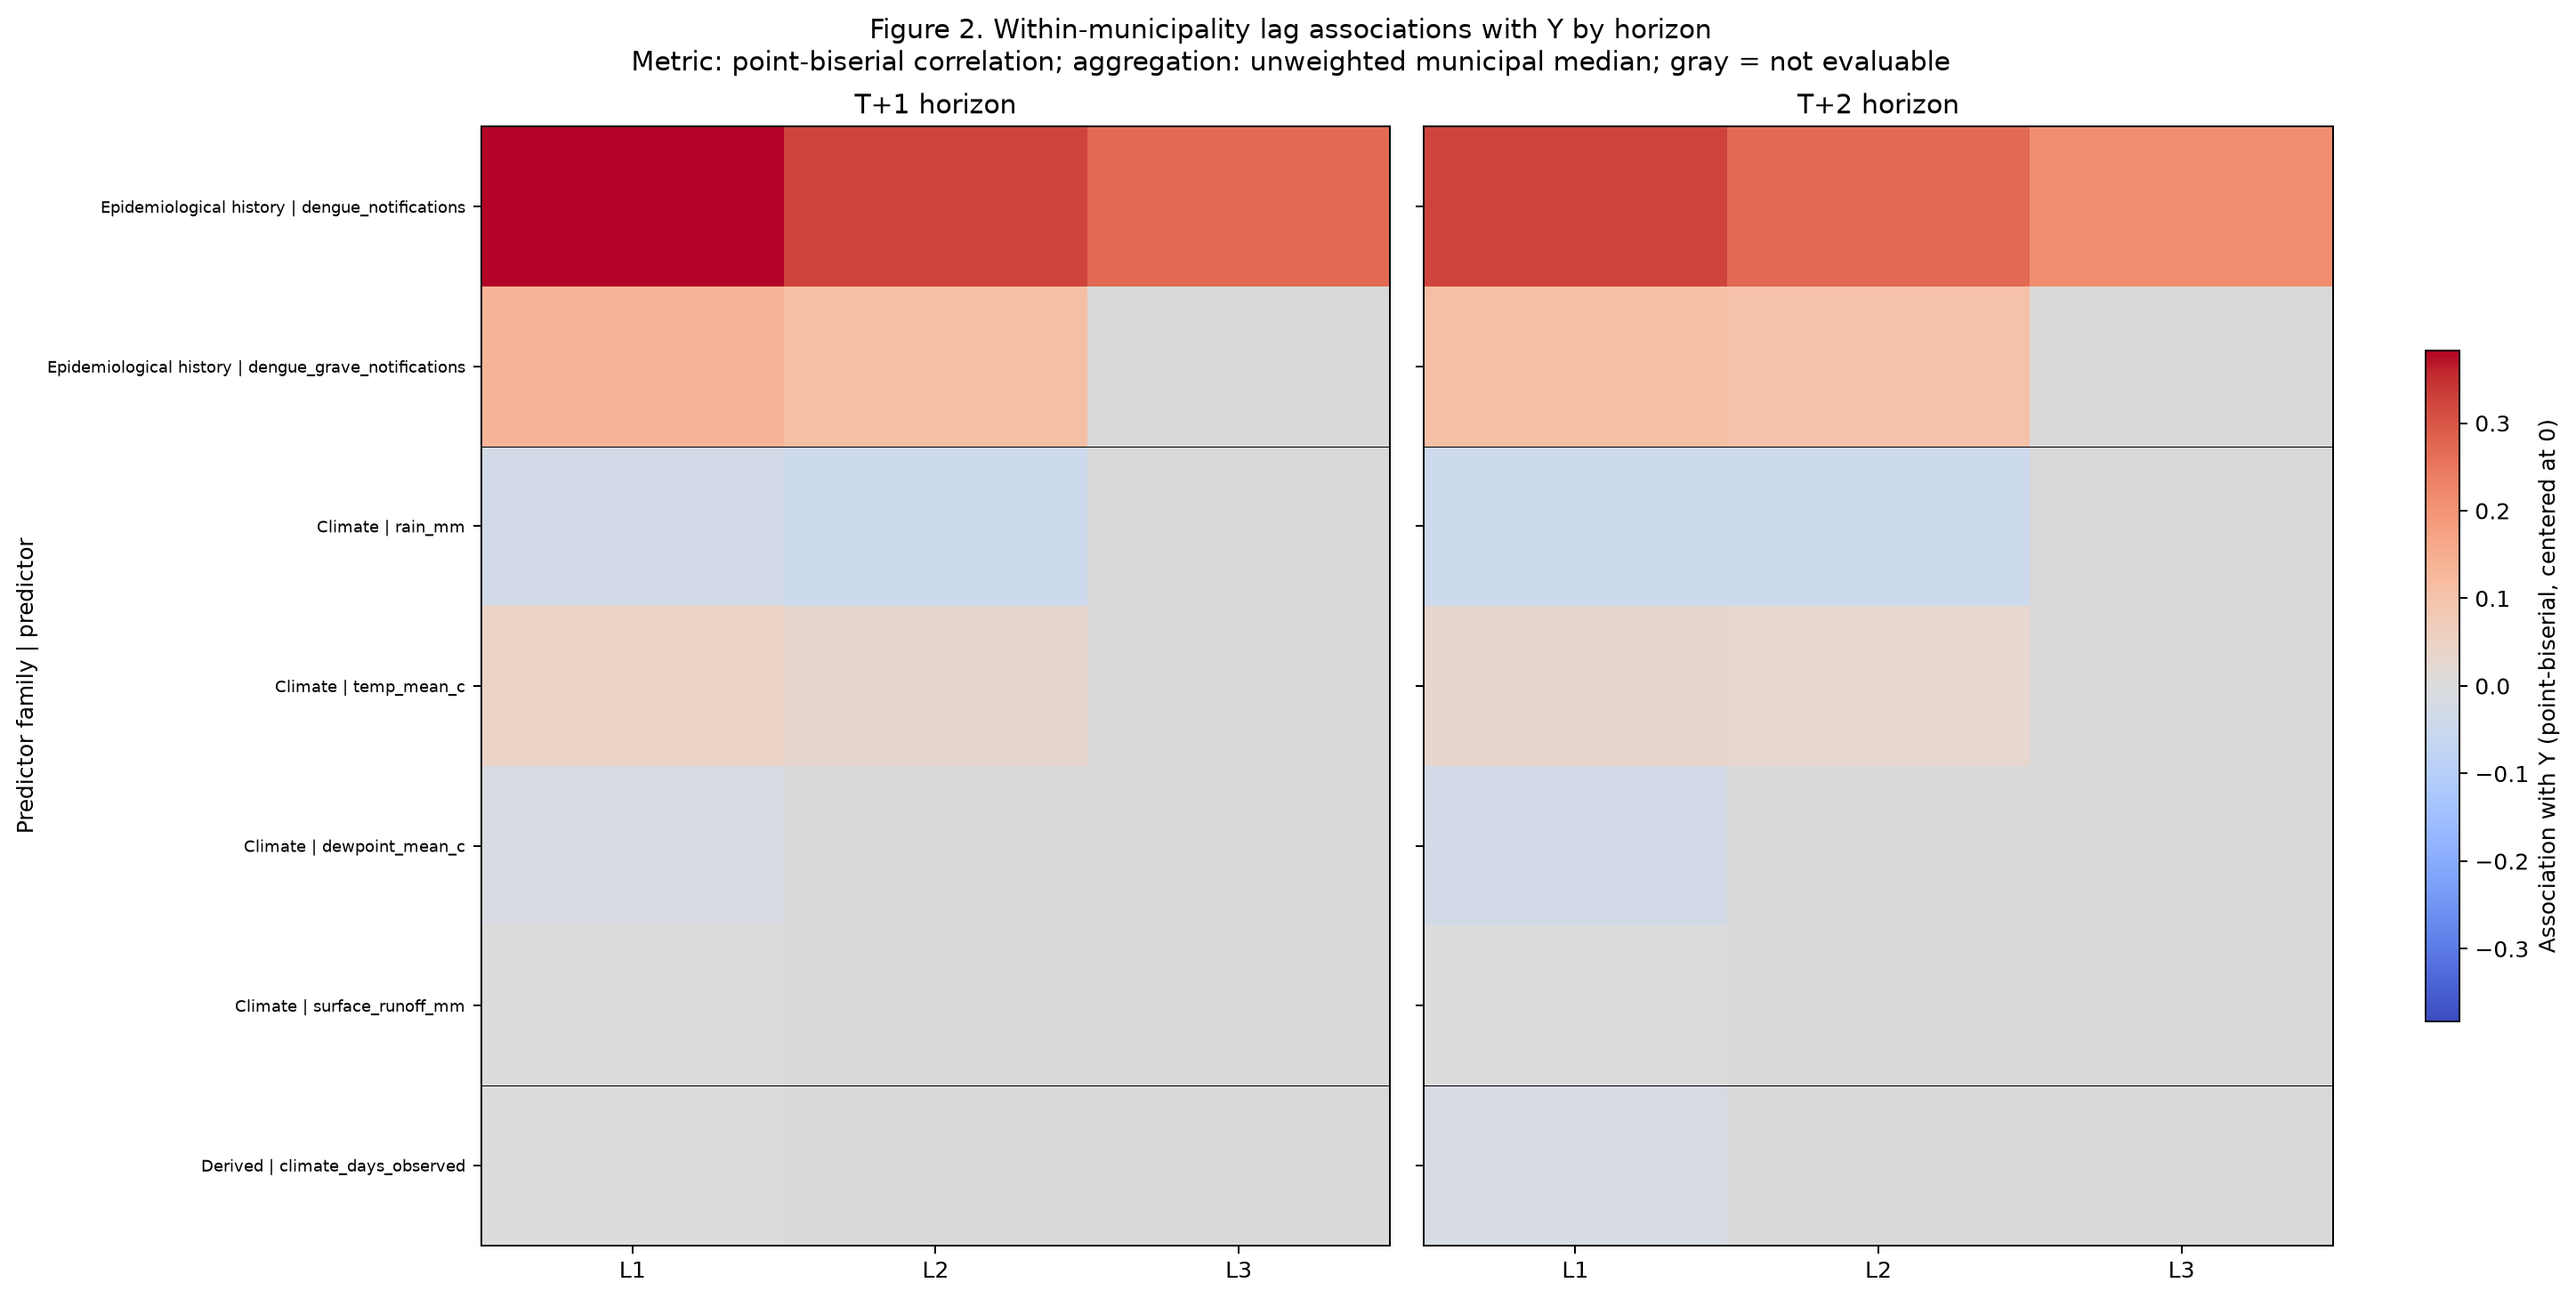

In [12]:
# Figura 2: asociaciones revisadas por municipio y resumidas entre municipios.
PREDICTOR_ORDER = [
    ("Epidemiological history", "dengue_notifications"),
    ("Epidemiological history", "dengue_grave_notifications"),
    ("Climate", "rain_mm"), ("Climate", "temp_mean_c"), ("Climate", "dewpoint_mean_c"),
    ("Climate", "surface_runoff_mm"), ("Derived", "climate_days_observed"),
]

def plot_associations(associations: pd.DataFrame):
    """Reconstruye los mapas de ambos horizontes sin recalcular asociaciones.

    Args:
        associations: 24 estimaciones revisadas con su soporte municipal.

    Returns:
        Figura y matrices de ambos horizontes.
    """
    row_labels = [family + " | " + predictor for family, predictor in PREDICTOR_ORDER]
    matrices = {}
    for horizon in ("t1", "t2"):
        frame = associations[associations.horizon.eq(horizon)].copy()
        frame["row_label"] = frame.family + " | " + frame.predictor
        frame["lag_label"] = frame.lag_months.map(lambda value: f"L{int(value)}")
        matrices[horizon] = frame.pivot(index="row_label", columns="lag_label", values="association_point_biserial_median").reindex(index=row_labels, columns=["L1", "L2", "L3"])
    combined = np.concatenate([m.to_numpy().ravel() for m in matrices.values()])
    vmax = float(np.nanmax(np.abs(combined))) or 1.0
    fig, axes = plt.subplots(1, 2, figsize=(16, 8), dpi=180, sharey=True, constrained_layout=True)
    for ax, horizon in zip(axes, ("t1", "t2")):
        cmap = plt.colormaps["coolwarm"].copy()
        cmap.set_bad("#d9d9d9")
        image = ax.imshow(np.ma.masked_invalid(matrices[horizon].to_numpy()), aspect="auto", interpolation="nearest", cmap=cmap, vmin=-vmax, vmax=vmax)
        ax.set_xticks(range(3), ["L1", "L2", "L3"])
        ax.set_yticks(range(len(row_labels)), row_labels, fontsize=7)
        ax.set_title("T+1 horizon" if horizon == "t1" else "T+2 horizon")
        for boundary in [1.5, 5.5]:
            ax.axhline(boundary, color="black", linewidth=0.4)
    axes[0].set_ylabel("Predictor family | predictor")
    fig.suptitle("Figure 2. Within-municipality lag associations with Y by horizon\n"
                 "Metric: point-biserial correlation; aggregation: unweighted municipal median; gray = not evaluable")
    fig.colorbar(image, ax=axes.ravel().tolist(), shrink=0.6).set_label("Association with Y (point-biserial, centered at 0)")
    return fig, matrices

show_text("Relación de los antecedentes con el exceso futuro")
association_figure, association_matrices = plot_associations(frames["associations"])
plt.show()
plt.close(association_figure)

In [13]:
show_text(reviewed["narratives"]['chapter7'])

In [14]:
show_text(reviewed["narratives"]['chapter8'])

In [15]:
# Tabla 2: conserva el título actualizado de la vista actual.
temporal = frames["temporal"]
temporal_table = temporal[["train_end", "horizon", "train_rows", "validation_rows", "temporal_validation_result"]].copy()
temporal_table["horizon"] = temporal_table["horizon"].str.upper()
temporal_table.columns = ["Corte de ajuste", "Horizonte", "Ejemplos para ajustar", "Ejemplos para validar", "Control temporal"]
show_text(reviewed["context"]["presentation"]["componentTitles"].get("chapter8-table", "Ocho comprobaciones temporales aprobadas"))
show_table(temporal_table)

Corte de ajuste,Horizonte,Ejemplos para ajustar,Ejemplos para validar,Control temporal
2018-12,T1,6384,456,PASS
2018-12,T2,6384,380,PASS
2020-12,T1,8208,456,PASS
2020-12,T2,8208,380,PASS
2022-12,T1,10032,456,PASS
2022-12,T2,10032,380,PASS
2024-06,T1,11400,456,PASS
2024-06,T2,11400,380,PASS


In [16]:
show_text(reviewed["narratives"]['chapter9'])

In [17]:
show_text(reviewed["narratives"]['chapter10'])

In [18]:
show_text(reviewed["narratives"]['decisions'])

In [19]:
# Validaciones de fidelidad de esta exportación (no son nuevas pruebas del pipeline).
assert reviewed["context"]["viewUrl"] == "http://127.0.0.1:4187/?view=1"
assert not reviewed["context"]["presentation"]["filters"]
assert not reviewed["context"]["presentation"]["hiddenBlocks"]
assert not reviewed["context"]["presentation"]["chartOverrides"]
assert len(frames["categories"]) == 69
assert len(seasonality_profile) == 912
assert not seasonality_profile.duplicated(["municipality_code", "calendar_month"]).any()
assert seasonality_profile.municipality_code.nunique() == 76
expected_peaks = seasonality_profile.loc[seasonality_profile.groupby("municipality_code").dengue_notifications_count.idxmax()]
expected_peaks = expected_peaks.sort_values("municipality_code").reset_index(drop=True)
pd.testing.assert_frame_equal(expected_peaks[frames["seasonality"].columns], frames["seasonality"].sort_values("municipality_code").reset_index(drop=True), check_dtype=False)
assert seasonality_matrix.shape == (76, 12), "Restablece municipality_codes=None para validar la vista original"
assert np.isclose(np.nanmin(seasonality_matrix), 0.0)
assert np.isclose(np.nanmax(seasonality_matrix), 1.0)
for row in frames["associations"].itertuples():
    row_label = row.family + " | " + row.predictor
    actual = association_matrices[row.horizon].loc[row_label, f"L{row.lag_months}"]
    assert np.isclose(actual, row.association_point_biserial_median)
assert sum(int(m.notna().sum().sum()) for m in association_matrices.values()) == 24
assert len(temporal_table) == 8
assert temporal.temporal_validation_result.eq("PASS").all()
assert temporal.groupby("horizon").validation_rows.unique().map(list).to_dict() == {"t1": [456], "t2": [380]}
assert temporal.validation_reference_before_cutoff_count.eq(0).all()
assert len(missing_table) == 11
assert np.isclose(frames["overview"].iloc[0].supervised_excess_pct, 4056 / 11856 * 100)
show_text("Verificación de la exportación\n\nPASS: 11 conjuntos revisados, 12 narrativas, 69 columnas inventariadas, "
          "912 celdas estacionales, 24 asociaciones y ocho escenarios temporales reproducidos. "
          "Dos figuras reconstruidas con código editable y dos tablas. Sin entrenamiento ni consultas nuevas.")

In [20]:
# Procedencia e instrucciones para otra computadora.
show_text("Fuentes y reproducción\n\nEsta es una copia fija de la vista capturada; modificar el informe web no actualiza este notebook. "
          "Ejecuta las celdas en orden desde un kernel nuevo. "
          "Para editar figuras, cambia plot_seasonality o plot_associations; sus datos están en seasonality_profile y frames. "
          "Para editar explicaciones, modifica reviewed['narratives'] o las llamadas show_text. "
          "La instantánea completa está incluida y no necesita archivos del repositorio, conexión a internet o credenciales.")
print(json.dumps({
    "vista": reviewed["context"]["viewUrl"],
    "identidad": reviewed["context"]["artifact"]["id"],
    "version_contexto": reviewed["context"]["contextVersion"],
    "sha256_instantanea": BUNDLE_SHA256,
    "fuente_perfil_estacional": reviewed["supplemental_profile"],
    "correccion_diccionario": reviewed["dictionary_correction"],
    "entorno": {"python": platform.python_version(), **{name: importlib.metadata.version(name) for name in ["pandas", "numpy", "matplotlib", "ipykernel"]}},
}, indent=2, ensure_ascii=False))

{
  "vista": "http://127.0.0.1:4187/?view=1",
  "identidad": "report:2b993d8b-f15c-4960-9286-480c449eab11",
  "version_contexto": "mvfxhvdy-lg0zl2f0919:1",
  "sha256_instantanea": "3fc98d6f61252e091192c261725995f1a4e702ef12b988e3a94bc4e8349ef4f4",
  "fuente_perfil_estacional": {
    "reason": "Existing reviewed chart input; the app query stores only 76 peak-month rows, insufficient to regenerate all 912 cells. Reused the exact existing source artifact, not a fresh extraction.",
    "sha256": "69a49883f1bc0502c3fabd8949321010a8f6d46f94346bc7123e3a8b2a06164c",
    "source": "/Users/mauriciorodriguez/Projects/AI-Masters/SAT-Dengue-V2/tmp/stage2_y_reconciliation/chapter4_seasonality_profile_raw.csv"
  },
  "correccion_diccionario": {
    "documented_fields": 69,
    "note": "All 69 fields are documented in the active canonical matrix; 63 official concepts/aliases and six insufficient operational definitions. The 59 default notebook role labels do not establish absent definitions.",
    "of